# Demo Chương 7 — Model Deployment and Prediction Service

Mọi thí nghiệm chạy trên **CPU, 1 thread**, dùng dataset `digits` có sẵn trong scikit-learn. Mỗi biểu đồ được lưu vào `figures` và mỗi bảng số liệu được lưu vào `results` để đưa thẳng vào slide.

**Quy ước đo:** mọi số đo latency dùng chung hàm `bench_bs` (cùng số lần warm-up và lặp), baseline FP32 batch size 1 chỉ đo **một lần** (`B1_BASE`) rồi dùng lại ở mọi bảng; "kích thước" là kích thước state dict đã tuần tự hóa (không phải RAM khi inference); các phần mô phỏng (hybrid cache, edge, chi phí cloud) đều ghi rõ giả định.

## Setup

In [20]:
import os, io, time, copy, math, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torch.nn.utils.prune as prune
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from IPython.display import display

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(1)          # 1 thread -> số đo ổn định, dễ so sánh

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

# Engine cho quantization: ưu tiên onednn, sau đó x86 / fbgemm / qnnpack (tùy máy hỗ trợ)
supported = torch.backends.quantized.supported_engines
for eng in ["onednn", "x86", "fbgemm", "qnnpack"]:
    if eng in supported:
        torch.backends.quantized.engine = eng
        break
print("Engine hỗ trợ:", supported, "| đang dùng:", torch.backends.quantized.engine)

RESULTS = {}   # nơi gom các con số chính cho phần tổng hợp

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def benchmark(fn, n=200, warmup=20):
    # Đo latency (ms) của fn(): warm-up trước, rồi lặp n lần. Trả về p50/p95/p99/mean.
    for _ in range(warmup):
        fn()
    t = np.empty(n)
    for i in range(n):
        s = time.perf_counter(); fn(); t[i] = (time.perf_counter() - s) * 1000
    return {"p50": np.percentile(t, 50), "p95": np.percentile(t, 95),
            "p99": np.percentile(t, 99), "mean": t.mean(), "samples": t}

def run(model, x):
    with torch.inference_mode():
        return model(x)

BENCH_N, BENCH_WARMUP = 500, 30           # dùng chung cho batch size <= 64
BENCH_N_BIG, BENCH_WARMUP_BIG = 100, 10   # dùng chung cho batch lớn

def torch_fn(model):
    return lambda x: run(model, x)

def bench_bs(model_fn, bs):
    # Hàm đo DUY NHẤT cho mọi model và batch size; model_fn nhận tensor torch
    n, w = (BENCH_N, BENCH_WARMUP) if bs <= 64 else (BENCH_N_BIG, BENCH_WARMUP_BIG)
    x = X_pool[:bs]
    return benchmark(lambda: model_fn(x), n=n, warmup=w)

# --- Thông tin máy: đưa 1 dòng này lên slide để số đo đáng tin ---
SYSINFO = (f"{platform.processor() or platform.machine()} | {os.cpu_count()} logical CPUs | "
           f"{platform.system()} | Python {platform.python_version()} | torch {torch.__version__} | "
           f"1 thread | quant engine: {torch.backends.quantized.engine}")
print(SYSINFO)

Engine hỗ trợ: ['onednn'] | đang dùng: onednn
Intel64 Family 6 Model 186 Stepping 2, GenuineIntel | 16 logical CPUs | Windows | Python 3.11.17 | torch 2.14.1+cpu | 1 thread | quant engine: onednn


## 0. Dữ liệu và model gốc (dùng chung cho mọi demo)
MLP `64 → 2048 → 2048 → 10` (~4.3M tham số, ~17 MB) huấn luyện trên `digits`. Model hơi to so với bài toán để các khác biệt về latency/kích thước đủ rõ khi đo. Dữ liệu test được nhân lên thành **pool 4096 mẫu** để đo throughput.

In [21]:
digits = load_digits()
X = (digits.data / 16.0).astype(np.float32); y = digits.target.astype(np.int64)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
X_train, X_test = torch.from_numpy(X_tr), torch.from_numpy(X_te)
y_train, y_test = torch.from_numpy(y_tr), torch.from_numpy(y_te)

POOL = 4096
X_pool = X_test.repeat(int(np.ceil(POOL / len(X_test))), 1)[:POOL].contiguous()

def make_mlp(hidden):
    return nn.Sequential(nn.Linear(64, hidden), nn.ReLU(),
                         nn.Linear(hidden, hidden), nn.ReLU(),
                         nn.Linear(hidden, 10))

def train(model, X, y, epochs=25, lr=1e-3, bs=64, teacher=None, T=4.0, alpha=0.7):
    # Huấn luyện bình thường, hoặc distillation nếu truyền teacher.
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = len(X)
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]; xb, yb = X[idx], y[idx]
            out = model(xb)
            if teacher is None:
                loss = F.cross_entropy(out, yb)
            else:
                with torch.no_grad():
                    t_logits = teacher(xb)
                soft = F.kl_div(F.log_softmax(out / T, 1), F.softmax(t_logits / T, 1),
                                reduction="batchmean") * T * T
                loss = alpha * soft + (1 - alpha) * F.cross_entropy(out, yb)
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    return model

@torch.no_grad()
def accuracy(model, X, y):
    model.eval()
    return (model(X).argmax(1) == y).float().mean().item()

def size_mb(model):
    buf = io.BytesIO(); torch.save(model.state_dict(), buf)
    return buf.tell() / 1e6

def n_params(model):
    return sum(p.numel() for p in model.parameters())

def n_nonzero(model):
    return sum((p != 0).sum().item() for p in model.parameters())

t0 = time.time()
base = train(make_mlp(2048), X_train, y_train, epochs=25)
print(f"Huấn luyện xong trong {time.time() - t0:.0f}s")
RESULTS["base_acc"] = accuracy(base, X_test, y_test) * 100
RESULTS["base_params"] = n_params(base)
RESULTS["base_size_mb"] = size_mb(base)
print(f"Accuracy test: {RESULTS['base_acc']:.2f}% | tham số: {RESULTS['base_params']:,} | state dict: {RESULTS['base_size_mb']:.1f} MB")

# Độ phân giải của tập test: chênh lệch accuracy nhỏ hơn ~1 điểm giữa các model đơn lẻ chưa có ý nghĩa
se = np.sqrt(RESULTS["base_acc"] / 100 * (1 - RESULTS["base_acc"] / 100) / len(y_test)) * 100
print(f"Tập test {len(y_test)} mẫu: 1 mẫu = {100 / len(y_test):.3f} điểm; sai số chuẩn ≈ {se:.2f} điểm")

with torch.no_grad():
    T_LOGITS = base(X_train)     # teacher cố định → tính logits một lần, dùng cho distillation

Huấn luyện xong trong 23s
Accuracy test: 98.33% | tham số: 4,349,962 | state dict: 17.4 MB
Tập test 540 mẫu: 1 mẫu = 0.185 điểm; sai số chuẩn ≈ 0.55 điểm


# Phần 1 — Batch Prediction vs Online Prediction
 online tối ưu latency, batch tối ưu throughput. Batch còn làm giảm latency vì lấy kết quả đã tính sẵn nhanh hơn tính mới. Phần này kiểm chứng bằng số đo thật.

### 1.1 Online prediction: latency của từng request (batch size = 1)

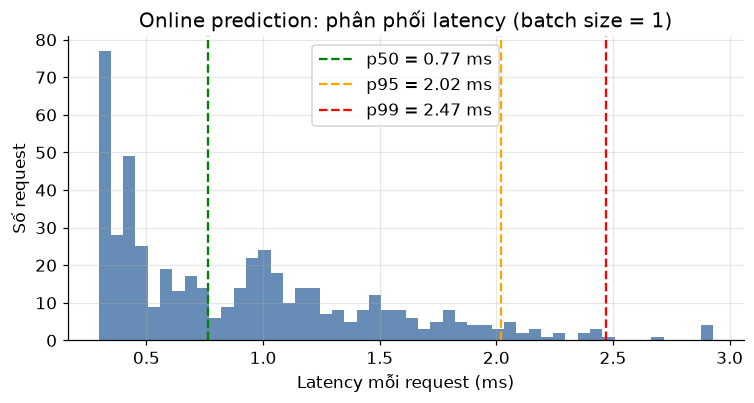

p50=0.766 ms | p95=2.019 ms | p99=2.470 ms


In [22]:
B1_BASE = bench_bs(torch_fn(base), 1)      # BASELINE duy nhất, dùng lại ở mọi bảng/biểu đồ sau
b_online = B1_BASE
RESULTS["fp32_bs1_p50"] = B1_BASE["p50"]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(b_online["samples"], bins=50, color="#4C78A8", alpha=0.85)
for q, c in [("p50", "green"), ("p95", "orange"), ("p99", "red")]:
    ax.axvline(b_online[q], color=c, ls="--", label=f"{q} = {b_online[q]:.2f} ms")
ax.set_xlabel("Latency mỗi request (ms)"); ax.set_ylabel("Số request")
ax.set_title("Online prediction: phân phối latency (batch size = 1)")
ax.legend()
savefig("fig1_online_latency_hist")
print(f"p50={b_online['p50']:.3f} ms | p95={b_online['p95']:.3f} ms | p99={b_online['p99']:.3f} ms")

### 1.2 Batch prediction: throughput và latency khi tăng batch size

,batch_size,latency_batch_p50_ms,latency_per_sample_ms,throughput_samples_per_s
0,1,0.7662,0.7662,1305.0571
1,4,1.5127,0.3782,2644.3658
2,16,2.4890,0.1556,6428.2845
3,64,6.5666,0.1026,9746.2918
4,256,23.7945,0.0929,10758.8114
5,1024,93.1292,0.0909,10995.4713
6,4096,307.7429,0.0751,13309.8115


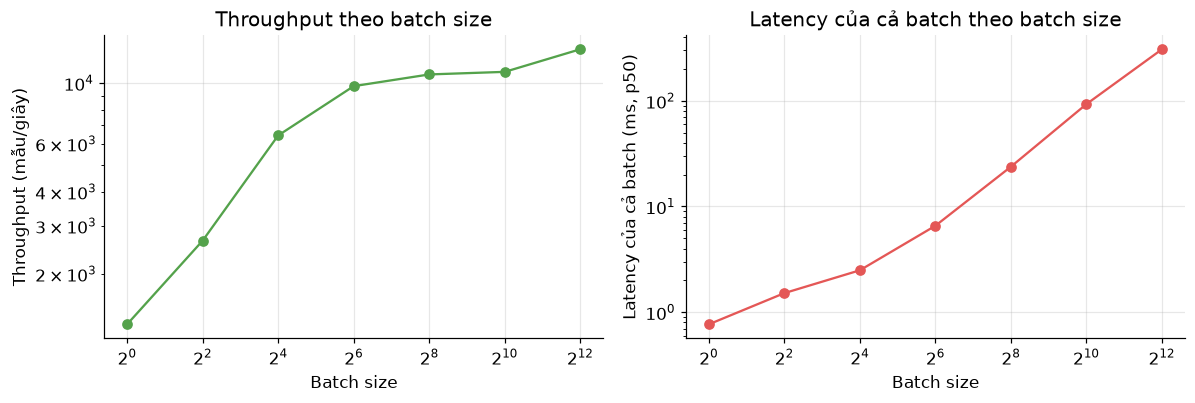

Throughput tăng 10.2x khi đi từ batch size 1 lên 4096


In [23]:
rows = []
for bs in [1, 4, 16, 64, 256, 1024, 4096]:
    b = B1_BASE if bs == 1 else bench_bs(torch_fn(base), bs)
    rows.append({"batch_size": bs, "latency_batch_p50_ms": b["p50"],
                 "latency_per_sample_ms": b["p50"] / bs,
                 "throughput_samples_per_s": bs / (b["p50"] / 1000)})
df_batch = pd.DataFrame(rows)
display(df_batch.round(4))
df_batch.to_csv("results/batch_vs_online.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(df_batch.batch_size, df_batch.throughput_samples_per_s, "o-", color="#54A24B")
axes[0].set_xscale("log", base=2); axes[0].set_yscale("log")
axes[0].set_xlabel("Batch size"); axes[0].set_ylabel("Throughput (mẫu/giây)")
axes[0].set_title("Throughput theo batch size")
axes[1].plot(df_batch.batch_size, df_batch.latency_batch_p50_ms, "o-", color="#E45756")
axes[1].set_xscale("log", base=2); axes[1].set_yscale("log")
axes[1].set_xlabel("Batch size"); axes[1].set_ylabel("Latency của cả batch (ms, p50)")
axes[1].set_title("Latency của cả batch theo batch size")
savefig("fig2_batch_throughput_latency")

best = df_batch.loc[df_batch.throughput_samples_per_s.idxmax()]
RESULTS["best_batch_size"] = int(best.batch_size)
RESULTS["throughput_bs1"] = float(df_batch.throughput_samples_per_s.iloc[0])
RESULTS["throughput_best"] = float(best.throughput_samples_per_s)
print(f"Throughput tăng {RESULTS['throughput_best'] / RESULTS['throughput_bs1']:.1f}x khi đi từ batch size 1 lên {RESULTS['best_batch_size']}")

### 1.3 Batch prediction giảm latency: precompute vs on-demand
Giả sử có 4096 người dùng. Hai cách phục vụ: (a) tính từng request khi họ vào (online), (b) tính sẵn một lần bằng batch rồi chỉ việc tra bảng (lookup).
> *Lưu ý:* lookup ở đây là dict trong bộ nhớ, **chưa tính** thời gian truy cập DB/cache qua mạng (khoảng vài trăm µs đến vài ms). Phần 1.4 sẽ tính đến điều này.

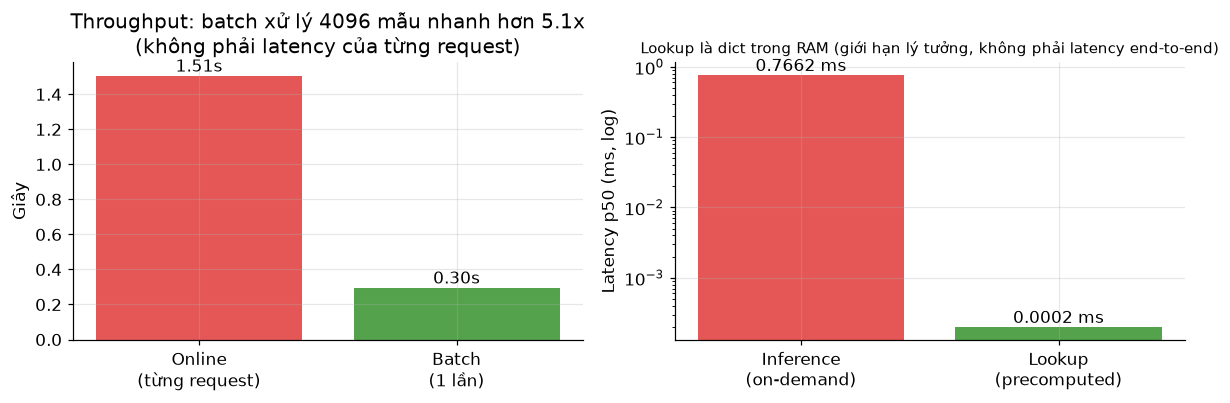

In [24]:
# (a) Tổng thời gian cho 4096 mẫu: online từng request vs batch
def serve_online_loop():
    with torch.inference_mode():
        for i in range(POOL):
            base(X_pool[i:i + 1])

runs = []                                   # ĐO THẬT vòng lặp 4096 request đơn lẻ (không ngoại suy từ p50)
for _ in range(5):
    s0 = time.perf_counter(); serve_online_loop(); runs.append(time.perf_counter() - s0)
t_online_total = float(np.median(runs))
b_bulk = benchmark(lambda: run(base, X_pool), n=20, warmup=3)
t_batch_total = b_bulk["p50"] / 1000

# (b) Precompute -> lookup
preds = run(base, X_pool).argmax(1).numpy()
table = {i: int(p) for i, p in enumerate(preds)}
k = [0]
def lookup():
    i = k[0] % POOL; k[0] += 1
    return table[i]
b_lookup = benchmark(lookup, n=5000, warmup=100)
RESULTS["lookup_p50_ms"] = b_lookup["p50"]
RESULTS["batch_total_speedup"] = t_online_total / t_batch_total

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(["Online\n(từng request)", "Batch\n(1 lần)"], [t_online_total, t_batch_total], color=["#E45756", "#54A24B"])
for i, v in enumerate([t_online_total, t_batch_total]):
    axes[0].text(i, v, f"{v:.2f}s", ha="center", va="bottom")
axes[0].set_ylabel("Giây"); axes[0].set_title(f"Throughput: batch xử lý {POOL} mẫu nhanh hơn {RESULTS['batch_total_speedup']:.1f}x\n(không phải latency của từng request)")
axes[1].bar(["Inference\n(on-demand)", "Lookup\n(precomputed)"], [b_online["p50"], b_lookup["p50"]], color=["#E45756", "#54A24B"])
axes[1].set_yscale("log"); axes[1].set_ylabel("Latency p50 (ms, log)")
axes[1].set_title("Lookup là dict trong RAM (giới hạn lý tưởng, không phải latency end-to-end)", fontsize=10)
for i, v in enumerate([b_online["p50"], b_lookup["p50"]]):
    axes[1].text(i, v, f"{v:.4f} ms", ha="center", va="bottom")
savefig("fig3_precompute_vs_ondemand")

### 1.4 Giải pháp hybrid: precompute cho truy vấn phổ biến, online cho phần còn lại
Truy vấn thực tế thường theo phân phối **Zipf** (một số ít truy vấn chiếm đa số lưu lượng). Đây là **mô phỏng**; latency model lấy từ số đo ở trên, latency tra cache là **giả định 0.05 ms** (cache cục bộ kiểu Redis).

,cache_fraction,cached_items,hit_rate,avg_latency_ms
0,0.000,0,0.0000,0.7662
1,0.001,4,0.3191,0.5377
2,0.005,20,0.5142,0.3980
3,0.010,40,0.5914,0.3427
4,0.050,204,0.7579,0.2234
5,0.100,409,0.8205,0.1786
6,0.250,1024,0.8968,0.1239
7,0.500,2048,0.9504,0.0855
8,1.000,4096,1.0000,0.0500


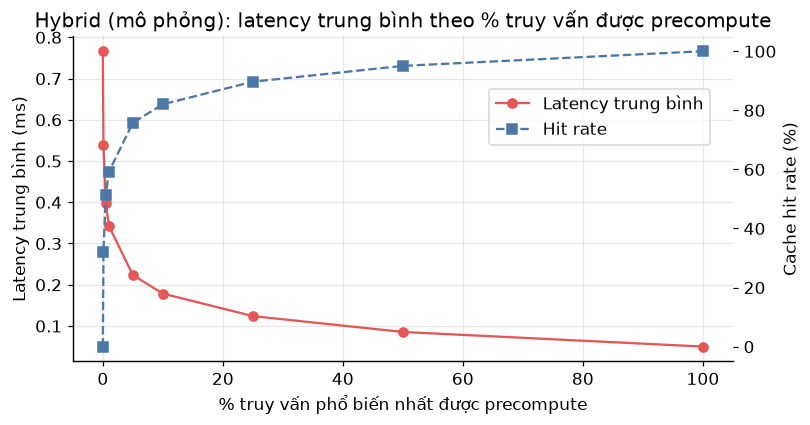

Cache 5% truy vấn → hit rate 76%, latency TB 0.223 ms (so với 0.766 ms khi 100% online)


In [25]:
KV_MS = 0.05                      # GIẢ ĐỊNH: latency tra cache
N_ITEMS, N_QUERIES, ZIPF_S = 4096, 50_000, 1.1
rng = np.random.RandomState(SEED)
p = np.arange(1, N_ITEMS + 1, dtype=float) ** -ZIPF_S; p /= p.sum()
queries = rng.choice(N_ITEMS, size=N_QUERIES, p=p)         # id nhỏ = truy vấn phổ biến

rows = []
for frac in [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.25, 0.5, 1.0]:
    K = int(frac * N_ITEMS)
    hit = (queries < K).mean()
    rows.append({"cache_fraction": frac, "cached_items": K, "hit_rate": hit,
                 "avg_latency_ms": hit * KV_MS + (1 - hit) * b_online["p50"]})
df_hybrid = pd.DataFrame(rows)
display(df_hybrid.round(4)); df_hybrid.to_csv("results/hybrid_cache.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(df_hybrid.cache_fraction * 100, df_hybrid.avg_latency_ms, "o-", color="#E45756", label="Latency trung bình")
ax.set_xlabel("% truy vấn phổ biến nhất được precompute"); ax.set_ylabel("Latency trung bình (ms)")
ax2 = ax.twinx(); ax2.plot(df_hybrid.cache_fraction * 100, df_hybrid.hit_rate * 100, "s--", color="#4C78A8", label="Hit rate")
ax2.set_ylabel("Cache hit rate (%)"); ax2.grid(False)
ax.set_title("Hybrid (mô phỏng): latency trung bình theo % truy vấn được precompute")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.8))
savefig("fig4_hybrid_cache")
r = df_hybrid[df_hybrid.cache_fraction == 0.05].iloc[0]
print(f"Cache 5% truy vấn → hit rate {r.hit_rate*100:.0f}%, latency TB {r.avg_latency_ms:.3f} ms (so với {b_online['p50']:.3f} ms khi 100% online)")

# Phần 2 — Model Compression
Bốn kỹ thuật phổ biến trong sách: **low-rank factorization, knowledge distillation, pruning, quantization**. Với mỗi kỹ thuật ta đo: kích thước state dict đã tuần tự hóa (MB), số tham số khác 0, accuracy, latency (batch size 1) và throughput (batch size 256).

Hàm `profile()` dưới đây dùng chung để tạo bảng so sánh cuối phần.

In [26]:
def profile(name, model, params_nonzero=None, params_total=None, b1=None, acc=None):
    model.eval()
    b1 = b1 if b1 is not None else bench_bs(torch_fn(model), 1)
    b256 = bench_bs(torch_fn(model), 256)
    return {"model": name,
            "state_dict_MB": size_mb(model),     # kích thước state dict đã tuần tự hóa, không phải RAM khi inference
            "params_total": params_total if params_total is not None else n_params(model),
            "params_nonzero": params_nonzero if params_nonzero is not None else n_nonzero(model),
            "accuracy_%": acc if acc is not None else accuracy(model, X_test, y_test) * 100,
            "latency_bs1_p50_ms": b1["p50"], "latency_bs1_p95_ms": b1["p95"],
            "throughput_bs256": 256 / (b256["p50"] / 1000)}

profiles = [profile("Baseline FP32", base, b1=B1_BASE)]   # dùng lại đúng phép đo ở mục 1.1
display(pd.DataFrame(profiles).round(3))

,model,state_dict_MB,params_total,params_nonzero,accuracy_%,latency_bs1_p50_ms,latency_bs1_p95_ms,throughput_bs256
0,Baseline FP32,17.403,4349962,4349962,98.333,0.766,2.019,13151.574


### 2.1 Quantization (INT8)
Giảm số bit biểu diễn mỗi tham số: FP32 → INT8. Sách nói đây là kỹ thuật **phổ biến và dễ làm nhất**, và cũng là bước tạo ra cải thiện lớn nhất trong case study Roblox (latency giảm 7 lần, throughput tăng 8 lần). Trước hết là phép tính lý thuyết ví dụ trong sách (100M tham số), sau đó là số đo thật.

In [27]:
# Lý thuyết: bộ nhớ cho 100M tham số ở các độ chính xác khác nhau
theory = pd.DataFrame({"Định dạng": ["FP32 (single)", "FP16 (half)", "INT8 (fixed point)", "1-bit (binary)"],
                       "Bit/tham số": [32, 16, 8, 1]})
theory["Bộ nhớ cho 100M tham số (MB)"] = 100e6 * theory["Bit/tham số"] / 8 / 1e6
display(theory)

# Thực tế: dynamic quantization các lớp Linear sang INT8
import torch.ao.nn.quantized.dynamic as nnqd

def n_nonzero_quantized(qmodel):
    # Đếm tham số khác 0 thật từ trọng số int8 (và bias) của các lớp Linear đã quantize
    total = 0
    for m in qmodel.modules():
        if isinstance(m, nnqd.Linear):
            total += (m.weight().int_repr() != 0).sum().item()
            if m.bias() is not None:
                total += (m.bias() != 0).sum().item()
    return total

q_model = torch.ao.quantization.quantize_dynamic(copy.deepcopy(base), {nn.Linear}, dtype=torch.qint8)
try:
    q_nz = n_nonzero_quantized(q_model)
except Exception:
    q_nz = float("nan")
profiles.append(profile("Quantized INT8", q_model, params_total=RESULTS["base_params"], params_nonzero=q_nz))
df = pd.DataFrame(profiles); display(df.round(3))

b, q = df.iloc[0], df.iloc[1]
RESULTS["int8_bs1_p50"] = q["latency_bs1_p50_ms"]
print(f"INT8: size giảm {b['state_dict_MB']/q['state_dict_MB']:.1f}x | latency bs1 giảm {b['latency_bs1_p50_ms']/q['latency_bs1_p50_ms']:.1f}x | "
      f"throughput tăng {q['throughput_bs256']/b['throughput_bs256']:.1f}x | accuracy {b['accuracy_%']:.2f}% → {q['accuracy_%']:.2f}%")


,Định dạng,Bit/tham số,Bộ nhớ cho 100M tham số (MB)
0,FP32 (single),32,400.0
1,FP16 (half),16,200.0
2,INT8 (fixed point),8,100.0
3,1-bit (binary),1,12.5


,model,state_dict_MB,params_total,params_nonzero,accuracy_%,latency_bs1_p50_ms,latency_bs1_p95_ms,throughput_bs256
0,Baseline FP32,17.403,4349962,4349962,98.333,0.766,2.019,13151.574
1,Quantized INT8,4.367,4349962,4171112,98.333,0.207,0.233,40379.823


INT8: size giảm 4.0x | latency bs1 giảm 3.7x | throughput tăng 3.1x | accuracy 98.33% → 98.33%


### 2.2 Pruning
Đặt các tham số ít quan trọng nhất (theo độ lớn |w|) về 0. Ta quét mức sparsity từ 0% đến 98%, **có và không** fine-tune lại sau khi cắt.

pruning không đổi kiến trúc, chỉ làm số tham số khác 0 giảm. Nếu vẫn lưu dạng dense thì kích thước file và latency hông đổi; chỉ khi dùng định dạng lưu/tính toán sparse mới có lợi.

,sparsity_%,acc_no_finetune_%,acc_finetune_%,params_nonzero
0,0.0,98.33,98.33,4349962
1,50.0,98.33,98.15,2177034
2,70.0,98.52,98.33,1307863
3,80.0,98.15,98.33,873277
4,90.0,96.67,98.15,438692
5,95.0,52.59,93.33,221399
6,98.0,13.70,23.15,91023


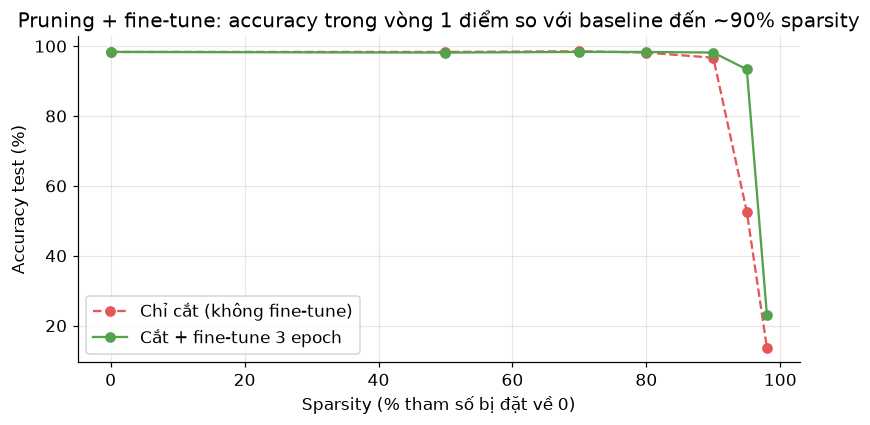

,model,state_dict_MB,params_total,params_nonzero,accuracy_%,latency_bs1_p50_ms,latency_bs1_p95_ms,throughput_bs256
2,Pruned 90% (dense storage),17.403,4349962,438692,98.148,0.364,0.498,13023.914


In [28]:
def linear_layers(m):
    return [mod for mod in m.modules() if isinstance(mod, nn.Linear)]

def prune_model(model, sparsity, finetune_epochs=0):
    m = copy.deepcopy(model)
    if sparsity > 0:
        prune.global_unstructured([(l, "weight") for l in linear_layers(m)],
                                  pruning_method=prune.L1Unstructured, amount=sparsity)
        if finetune_epochs > 0:
            train(m, X_train, y_train, epochs=finetune_epochs, lr=3e-4)   # mask vẫn giữ nguyên khi fine-tune
        for l in linear_layers(m):
            prune.remove(l, "weight")                                     # "đóng băng" mask vào weight
    m.eval()
    return m

pruned_models, rows = {}, []
for s in [0, 0.5, 0.7, 0.8, 0.9, 0.95, 0.98]:
    torch.manual_seed(SEED); m_raw = prune_model(base, s, finetune_epochs=0)
    torch.manual_seed(SEED); m_ft = prune_model(base, s, finetune_epochs=3)
    pruned_models[s] = m_ft                    # giữ lại đúng model này cho bảng tổng hợp
    rows.append({"sparsity_%": s * 100,
                 "acc_no_finetune_%": accuracy(m_raw, X_test, y_test) * 100,
                 "acc_finetune_%": accuracy(m_ft, X_test, y_test) * 100,
                 "params_nonzero": n_nonzero(m_ft)})
df_prune = pd.DataFrame(rows); display(df_prune.round(2)); df_prune.to_csv("results/pruning.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(df_prune["sparsity_%"], df_prune["acc_no_finetune_%"], "o--", color="#E45756", label="Chỉ cắt (không fine-tune)")
ax.plot(df_prune["sparsity_%"], df_prune["acc_finetune_%"], "o-", color="#54A24B", label="Cắt + fine-tune 3 epoch")
ax.set_xlabel("Sparsity (% tham số bị đặt về 0)"); ax.set_ylabel("Accuracy test (%)")
ok = df_prune[df_prune["acc_finetune_%"] >= df_prune["acc_finetune_%"].iloc[0] - 1.0]
ax.set_title(f"Pruning + fine-tune: accuracy trong vòng 1 điểm so với baseline đến ~{ok['sparsity_%'].max():.0f}% sparsity")
ax.legend()
savefig("fig5_pruning_sparsity_accuracy")

profiles.append(profile("Pruned 90% (dense storage)", pruned_models[0.9]))   # đúng model trong bảng pruning
display(pd.DataFrame(profiles).round(3).tail(1))

### 2.3 Low-rank factorization
Thay ma trận trọng số lớn `W (out×in)` bằng tích hai ma trận nhỏ `A (out×r) · B (r×in)` bằng SVD cắt rank.áp dụng cho lớp `2048×2048` ở giữa model.

,rank,params,param_ratio,accuracy_%
0,4,172042,0.040,64.259
1,8,188426,0.043,92.778
2,16,221194,0.051,98.333
3,32,286730,0.066,98.333
4,64,417802,0.096,98.333
5,128,679946,0.156,98.333
6,256,1204234,0.277,98.333
7,512,2252810,0.518,98.333


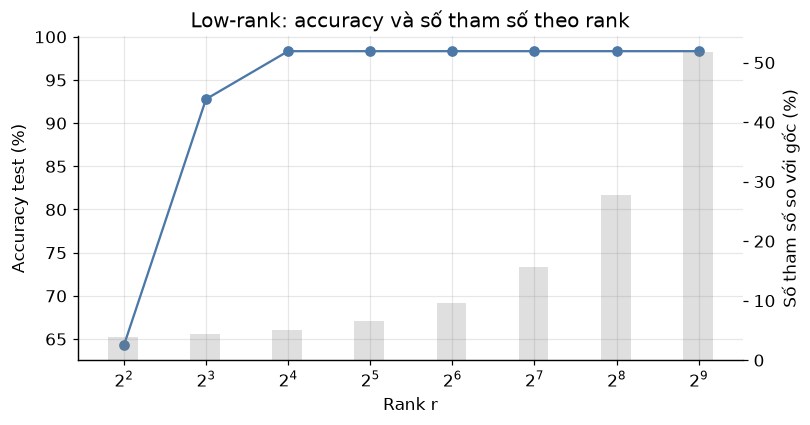

Conv chuẩn 3x3, C=N=256: 589,824 tham số | Depthwise separable: 67,840 tham số → giảm 8.7x (sách: 8–9x khi K=3)


In [29]:
def lowrank_linear(layer, r):
    W = layer.weight.data
    U, S, Vh = torch.linalg.svd(W, full_matrices=False)
    A = nn.Linear(layer.in_features, r, bias=False)
    B = nn.Linear(r, layer.out_features, bias=True)
    A.weight.data = (torch.diag(S[:r].sqrt()) @ Vh[:r]).clone()
    B.weight.data = (U[:, :r] @ torch.diag(S[:r].sqrt())).clone()
    B.bias.data = layer.bias.data.clone()
    return nn.Sequential(A, B)

def make_lowrank(model, r):
    m = copy.deepcopy(model)
    m[2] = lowrank_linear(m[2], r)       # chỉ lớp Linear(2048, 2048) ở giữa
    return m.eval()

rows = []
for r in [4, 8, 16, 32, 64, 128, 256, 512]:
    m = make_lowrank(base, r)
    rows.append({"rank": r, "params": n_params(m), "param_ratio": n_params(m) / n_params(base),
                 "accuracy_%": accuracy(m, X_test, y_test) * 100})
df_lr = pd.DataFrame(rows); display(df_lr.round(3)); df_lr.to_csv("results/lowrank.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(df_lr["rank"], df_lr["accuracy_%"], "o-", color="#4C78A8")
ax.set_xscale("log", base=2); ax.set_xlabel("Rank r"); ax.set_ylabel("Accuracy test (%)")
ax2 = ax.twinx(); ax2.bar(df_lr["rank"], df_lr["param_ratio"] * 100, width=df_lr["rank"] * 0.25, alpha=0.25, color="gray"); ax2.grid(False)
ax2.set_ylabel("Số tham số so với gốc (%)")
ax.set_title("Low-rank: accuracy và số tham số theo rank")
savefig("fig6_lowrank")

RANK = 64
profiles.append(profile(f"Low-rank (r={RANK})", make_lowrank(base, RANK), params_nonzero=n_params(make_lowrank(base, RANK))))

# MobileNet: depthwise separable convolution vs convolution chuẩn
C, N, K = 256, 256, 3
std = nn.Conv2d(C, N, K, bias=False)
sep = nn.Sequential(nn.Conv2d(C, C, K, groups=C, bias=False), nn.Conv2d(C, N, 1, bias=False))
print(f"Conv chuẩn {K}x{K}, C=N={C}: {n_params(std):,} tham số | Depthwise separable: {n_params(sep):,} tham số "
      f"/ giảm {n_params(std)/n_params(sep):.1f}x (sách: 8–9x khi K=3)")

### 2.4 Knowledge Distillation
Student nhỏ (`64→32→32→10`, ~3.4K tham số) học từ teacher (model gốc ~4.3M tham số) qua *soft labels* (T=4, alpha=0,7). Ta so sánh ba cách huấn luyện student, **ghép cặp theo seed** (cùng tập con dữ liệu có nhãn, cùng khởi tạo): **tự học**, **distillation trên mẫu có nhãn**, và **distillation có thêm các mẫu không nhãn** do teacher gán soft label. Quét tỷ lệ dữ liệu có nhãn 5% / 10% / 25%, lặp 20 seed. Kết quả báo cáo là trung bình ± sai số chuẩn và hiệu số ghép cặp; ta **không giả định trước** distillation có lợi.

Distillation xong trong 44s


,label_fraction,method,acc_alone_%,acc_method_%,paired_diff_mean,paired_diff_se
0,0.05,kd,70.20,54.03,-16.18,1.58
1,0.05,kd_unlab,70.20,66.70,-3.50,1.29
2,0.10,kd,85.31,80.24,-5.06,0.44
3,0.10,kd_unlab,85.31,85.69,0.38,0.47
4,0.25,kd,92.77,91.90,-0.87,0.27
5,0.25,kd_unlab,92.77,94.01,1.24,0.22


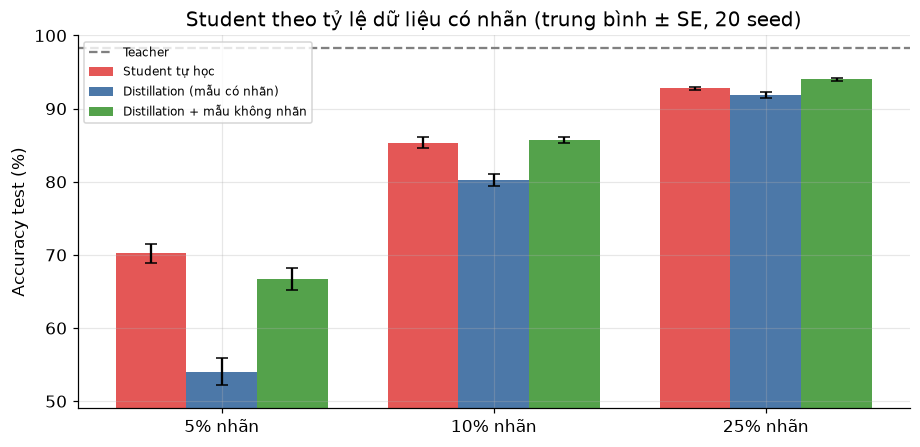

In [30]:
base.eval()
SEEDS = list(range(20))
FRACS = [0.05, 0.10, 0.25]
MODES = ["alone", "kd", "kd_unlab"]   # tự học | distill trên mẫu có nhãn | + mẫu không nhãn (teacher gán soft label)

def kd_loss(out, t_logits, T):
    return F.kl_div(F.log_softmax(out / T, 1), F.softmax(t_logits / T, 1), reduction="batchmean") * T * T

def train_student(seed, frac, mode, hidden=32, epochs=80, bs=32, T=4.0, alpha=0.7):
    torch.manual_seed(seed)
    perm = np.random.RandomState(seed).permutation(len(X_train))
    k = max(int(frac * len(X_train)), 10)
    lab, unl = perm[:k], perm[k:]
    Xl, yl, Tl = X_train[lab], y_train[lab], T_LOGITS[lab]
    Xu, Tu = X_train[unl], T_LOGITS[unl]
    s = make_mlp(hidden); opt = torch.optim.Adam(s.parameters(), lr=1e-3)
    for _ in range(epochs):
        s.train(); p = torch.randperm(len(Xl))
        for i in range(0, len(Xl), bs):
            idx = p[i:i + bs]; out = s(Xl[idx])
            if mode == "alone":
                loss = F.cross_entropy(out, yl[idx])
            else:
                loss = alpha * kd_loss(out, Tl[idx], T) + (1 - alpha) * F.cross_entropy(out, yl[idx])
            if mode == "kd_unlab":
                ju = torch.randint(0, len(Xu), (bs,))
                loss = loss + kd_loss(s(Xu[ju]), Tu[ju], T)
            opt.zero_grad(); loss.backward(); opt.step()
    return s.eval()

t0 = time.time()
KD_ACC = {(f, m): np.array([accuracy(train_student(sd, f, m), X_test, y_test) * 100 for sd in SEEDS])
          for f in FRACS for m in MODES}
print(f"Distillation xong trong {time.time() - t0:.0f}s")

teacher_acc = RESULTS["base_acc"]
rows = []
for f in FRACS:
    a0 = KD_ACC[(f, "alone")]
    for m in ["kd", "kd_unlab"]:
        d = KD_ACC[(f, m)] - a0                    # hiệu số ghép cặp theo seed
        rows.append({"label_fraction": f, "method": m, "acc_alone_%": a0.mean(), "acc_method_%": KD_ACC[(f, m)].mean(),
                     "paired_diff_mean": d.mean(), "paired_diff_se": d.std(ddof=1) / np.sqrt(len(d))})
df_kd = pd.DataFrame(rows); display(df_kd.round(2)); df_kd.to_csv("results/distillation.csv", index=False)

fig, ax = plt.subplots(figsize=(8.5, 4.2)); x = np.arange(len(FRACS)); w = 0.26
for j, (m, label, c) in enumerate([("alone", "Student tự học", "#E45756"),
                                   ("kd", "Distillation (mẫu có nhãn)", "#4C78A8"),
                                   ("kd_unlab", "Distillation + mẫu không nhãn", "#54A24B")]):
    means = [KD_ACC[(f, m)].mean() for f in FRACS]
    ses = [KD_ACC[(f, m)].std(ddof=1) / np.sqrt(len(SEEDS)) for f in FRACS]
    ax.bar(x + (j - 1) * w, means, w, yerr=ses, capsize=4, label=label, color=c)
ax.axhline(teacher_acc, color="gray", ls="--", label="Teacher")
ax.set_xticks(x); ax.set_xticklabels([f"{int(f * 100)}% nhãn" for f in FRACS])
ax.set_ylim(min(v.mean() for v in KD_ACC.values()) - 5, 100); ax.set_ylabel("Accuracy test (%)")
ax.set_title(f"Student theo tỷ lệ dữ liệu có nhãn (trung bình ± SE, {len(SEEDS)} seed)"); ax.legend(fontsize=8)
savefig("fig7_distillation")

# Dòng cho bảng compression: accuracy = trung bình nhiều seed; size/latency đo trên model seed 0 (do kiến trúc quyết định)
REP_FRAC = 0.25
student_rep = train_student(0, REP_FRAC, "kd")
mean_acc_kd = df_kd[(df_kd.label_fraction == REP_FRAC) & (df_kd.method == "kd")]["acc_method_%"].iloc[0]
profiles.append(profile(f"Student distilled (acc: TB {len(SEEDS)} seed; size/latency: seed 0)", student_rep, acc=mean_acc_kd))
q_student = torch.ao.quantization.quantize_dynamic(copy.deepcopy(student_rep), {nn.Linear}, dtype=torch.qint8)
try:
    qs_nz = n_nonzero_quantized(q_student)
except Exception:
    qs_nz = float("nan")
profiles.append(profile("Student distilled + INT8 (seed 0)", q_student, params_total=n_params(student_rep), params_nonzero=qs_nz))

### 2.5 Tổng hợp Model Compression (bảng + biểu đồ chính cho slide)

,model,state_dict_MB,params_total,params_nonzero,accuracy_%,latency_bs1_p50_ms,latency_bs1_p95_ms,throughput_bs256
0,Baseline FP32,17.403,4349962,4349962,98.333,0.766,2.019,13151.574
1,Quantized INT8,4.367,4349962,4171112,98.333,0.207,0.233,40379.823
2,Pruned 90% (dense storage),17.403,4349962,438692,98.148,0.364,0.498,13023.914
3,Low-rank (r=64),1.674,417802,417802,98.333,0.079,0.261,102962.173
4,Student distilled (acc: TB 20 seed; size/laten...,0.017,3466,3466,91.898,0.029,0.036,5014691.532
5,Student distilled + INT8 (seed 0),0.008,3466,3440,91.481,0.126,0.209,1132743.362


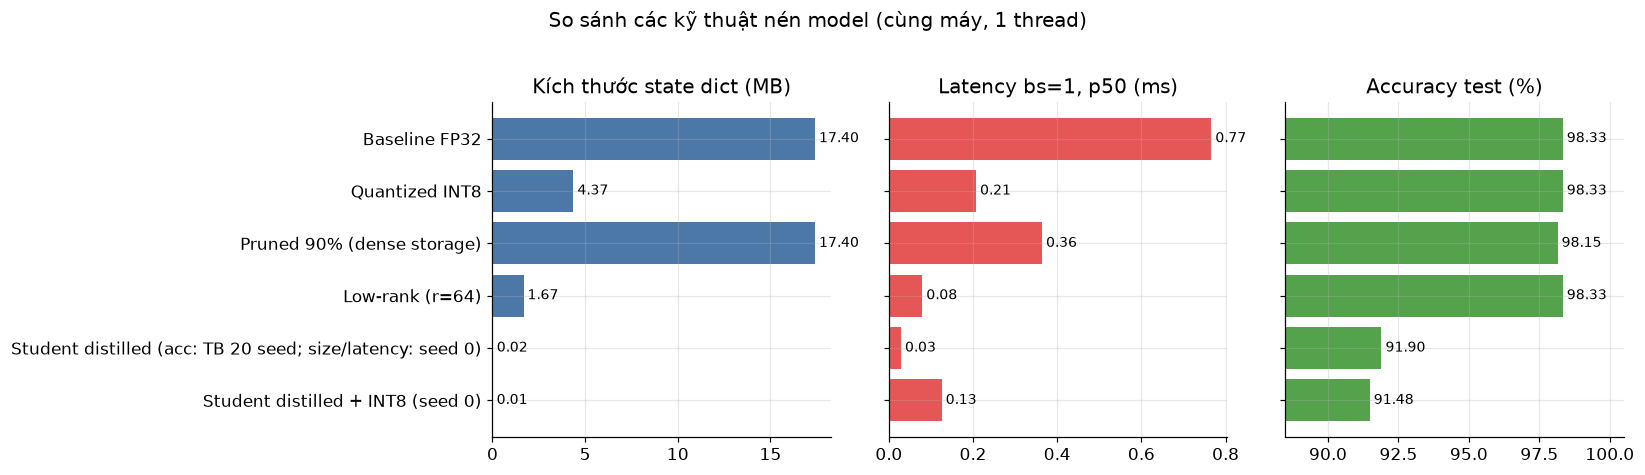

In [31]:
df_comp = pd.DataFrame(profiles); display(df_comp.round(3)); df_comp.to_csv("results/compression_summary.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
names = df_comp["model"]
for ax, col, title, color in [(axes[0], "state_dict_MB", "Kích thước state dict (MB)", "#4C78A8"),
                              (axes[1], "latency_bs1_p50_ms", "Latency bs=1, p50 (ms)", "#E45756"),
                              (axes[2], "accuracy_%", "Accuracy test (%)", "#54A24B")]:
    ax.barh(names, df_comp[col], color=color)
    for i, v in enumerate(df_comp[col]):
        ax.text(v, i, f" {v:.2f}", va="center", fontsize=9)
    ax.set_title(title); ax.invert_yaxis()
axes[2].set_xlim(min(df_comp["accuracy_%"]) - 3, 100.5)
fig.suptitle("So sánh các kỹ thuật nén model (cùng máy, 1 thread)", y=1.02)
savefig("fig8_compression_summary")

# Phần 3 — ML on the Cloud and on the Edge
(1) model phải được **biên dịch** (qua IR) để chạy hiệu quả trên phần cứng đích; (2) trên cloud, **network latency** thường lớn hơn inference latency; (3) **chi phí cloud** là động lực đẩy tính toán ra edge.

### 3.1 Compiler / Intermediate Representation: ONNX Runtime
Export model sang **ONNX** (một dạng IR trung gian giữa framework và phần cứng), rồi chạy bằng ONNX Runtime. So sánh ba cấu hình: PyTorch, ONNX Runtime **tắt** graph optimization, ONNX Runtime **bật** graph optimization

Đầu ra khớp PyTorch: True


,engine,latency_bs1_p50_ms,latency_bs256_p50_ms,throughput_bs256
0,PyTorch,0.766,19.992,12804.834
1,ONNX RT (tắt optimization),0.339,17.923,14282.964
2,ONNX RT (bật optimization),0.322,18.379,13928.562


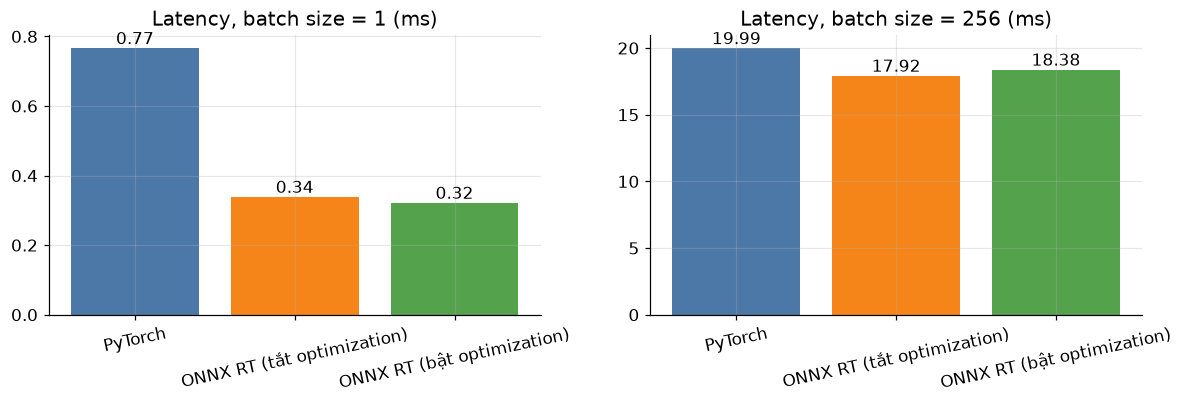

In [32]:
ONNX_OK = True
try:
    import onnxruntime as ort
    ONNX_PATH = "model.onnx"
    dummy = X_pool[:1]
    kwargs = dict(input_names=["input"], output_names=["output"],
                  dynamic_axes={"input": {0: "batch"}, "output": {0: "batch"}}, opset_version=17)
    try:
        torch.onnx.export(base, dummy, ONNX_PATH, dynamo=False, **kwargs)   # torch >= 2.5
    except TypeError:
        torch.onnx.export(base, dummy, ONNX_PATH, **kwargs)

    def make_session(level):
        so = ort.SessionOptions()
        so.intra_op_num_threads = 1; so.inter_op_num_threads = 1
        so.graph_optimization_level = level
        return ort.InferenceSession(ONNX_PATH, so, providers=["CPUExecutionProvider"])

    sess_off = make_session(ort.GraphOptimizationLevel.ORT_DISABLE_ALL)
    sess_on = make_session(ort.GraphOptimizationLevel.ORT_ENABLE_ALL)

    # kiểm tra đầu ra khớp với PyTorch
    ref = run(base, X_pool[:64]).numpy()
    out = sess_on.run(None, {"input": X_pool[:64].numpy()})[0]
    print("Đầu ra khớp PyTorch:", np.allclose(ref, out, atol=1e-3))

    engines_cfg = {"PyTorch": torch_fn(base),
                   "ONNX RT (tắt optimization)": lambda x: sess_off.run(None, {"input": x.numpy()}),
                   "ONNX RT (bật optimization)": lambda x: sess_on.run(None, {"input": x.numpy()})}
    rows = []
    for name, fn in engines_cfg.items():
        b1 = B1_BASE if name == "PyTorch" else bench_bs(fn, 1)    # cùng hàm đo, cùng baseline PyTorch
        b256 = bench_bs(fn, 256)
        rows.append({"engine": name, "latency_bs1_p50_ms": b1["p50"], "latency_bs256_p50_ms": b256["p50"],
                     "throughput_bs256": 256 / (b256["p50"] / 1000)})
    df_onnx = pd.DataFrame(rows); display(df_onnx.round(3)); df_onnx.to_csv("results/onnx_runtime.csv", index=False)
    RESULTS["ort_bs1_p50"] = float(df_onnx["latency_bs1_p50_ms"].iloc[2])

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    cols = ["#4C78A8", "#F58518", "#54A24B"]
    for ax, col, title in [(axes[0], "latency_bs1_p50_ms", "Latency, batch size = 1 (ms)"),
                           (axes[1], "latency_bs256_p50_ms", "Latency, batch size = 256 (ms)")]:
        ax.bar(df_onnx["engine"], df_onnx[col], color=cols)
        for i, v in enumerate(df_onnx[col]): ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
        ax.set_title(title); ax.tick_params(axis="x", rotation=12)
    savefig("fig9_onnx_runtime")
except ImportError as e:
    ONNX_OK = False
    print("Bỏ qua mục 3.1. Cài đặt: pip install onnx onnxruntime  |  chi tiết:", e)

### 3.2 Operator fusion ( Hình 7-13)
Tính `R = (A + s·B) · C`. Cách tạo 2 mảng tạm và duyệt dữ liệu 3 lần. Bản **chunked computation** xử lý theo từng khối nhỏ nằm gọn trong cache và tái sử dụng một buffer tạm (loop tiling); nó vẫn gọi ba phép NumPy riêng cho mỗi khối nên **không phải** một kernel fuse thật. Bản `numexpr` (ép về 1 luồng để so sánh công bằng) và bản `numba` một vòng lặp là hai bản gần với fusion thật hơn; cả hai là tùy chọn.

(Tùy chọn) pip install numba


,variant,time_ms_p50,speedup
0,"Không fuse (3 vòng lặp, 2 mảng tạm)",57.85,1.00
1,Chunked computation + tái sử dụng buffer,27.87,2.08
2,numexpr (1 luồng),40.78,1.42


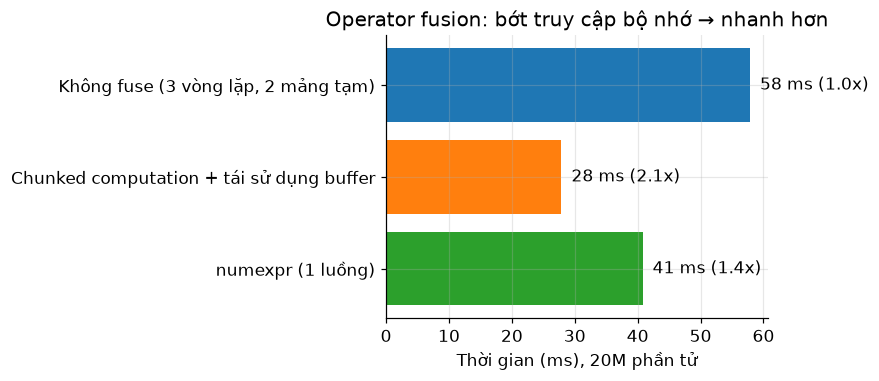

In [33]:
Nn = 20_000_000
rng = np.random.RandomState(0)
A, B, Cc = (rng.rand(Nn).astype(np.float32) for _ in range(3)); s = np.float32(2.0)

def unfused(A, B, C, s):
    t1 = s * B; t2 = A + t1; return t2 * C

def fused_chunked(A, B, C, s, chunk=1 << 15):
    R = np.empty_like(A); t = np.empty(chunk, dtype=A.dtype)
    for i in range(0, len(A), chunk):
        j = min(i + chunk, len(A)); n = j - i
        np.multiply(B[i:j], s, out=t[:n]); np.add(A[i:j], t[:n], out=t[:n]); np.multiply(t[:n], C[i:j], out=R[i:j])
    return R

assert np.allclose(unfused(A, B, Cc, s), fused_chunked(A, B, Cc, s), atol=1e-5)
variants = {"Không fuse (3 vòng lặp, 2 mảng tạm)": lambda: unfused(A, B, Cc, s),
            "Chunked computation + tái sử dụng buffer": lambda: fused_chunked(A, B, Cc, s)}
try:
    import numexpr as ne
    ne.set_num_threads(1)        # NumExpr mặc định đa luồng → ép 1 luồng để so sánh công bằng với các bản còn lại
    variants["numexpr (1 luồng)"] = lambda: ne.evaluate("(A + s * B) * C", local_dict={"A": A, "B": B, "C": Cc, "s": s})
except ImportError:
    print("(Tùy chọn) pip install numexpr")
try:
    from numba import njit

    @njit(cache=True)
    def fused_numba(A, B, C, s):          # một vòng lặp duy nhất = fusion thật
        R = np.empty_like(A)
        for i in range(A.shape[0]):
            R[i] = (A[i] + s * B[i]) * C[i]
        return R

    fused_numba(A[:16], B[:16], Cc[:16], s)       # biên dịch trước, không tính thời gian compile
    variants["Fused kernel 1 vòng lặp (numba)"] = lambda: fused_numba(A, B, Cc, s)
except ImportError:
    print("(Tùy chọn) pip install numba")

rows = []
for name, fn in variants.items():
    b = benchmark(fn, n=15, warmup=3); rows.append({"variant": name, "time_ms_p50": b["p50"]})
df_fuse = pd.DataFrame(rows); df_fuse["speedup"] = df_fuse["time_ms_p50"].iloc[0] / df_fuse["time_ms_p50"]
display(df_fuse.round(2)); df_fuse.to_csv("results/operator_fusion.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(df_fuse["variant"], df_fuse["time_ms_p50"], color=plt.cm.tab10.colors[:len(df_fuse)])
for i, (v, sp) in enumerate(zip(df_fuse["time_ms_p50"], df_fuse["speedup"])): ax.text(v, i, f"  {v:.0f} ms ({sp:.1f}x)", va="center")
ax.set_xlabel("Thời gian (ms), 20M phần tử"); ax.set_title("Operator fusion: bớt truy cập bộ nhớ → nhanh hơn"); ax.invert_yaxis()
savefig("fig10_operator_fusion")

### 3.3 Cloud vs Edge: network latency so với inference latency
Ta lấy inference latency **đo được** và cộng thêm RTT mạng **mô phỏng**. Edge không có RTT nhưng thiết bị yếu hơn server, nên inference được nhân với hệ số chậm **giả định ×3** và dùng model đã quantize INT8.
> Luu y: RTT và hệ số ×3 là **giả định minh họa**, cần ghi rõ "mô phỏng" trên slide. Latency Edge **không đo trên thiết bị thật**; mô phỏng này minh họa nhận định của sách chứ không kiểm chứng nó. Vì vậy ta tính thêm **ngưỡng hòa vốn**: edge phải chậm hơn server bao nhiêu lần thì cloud mới nhanh hơn, để kết luận không phụ thuộc vào hệ số ×3.

,scenario,where,network_ms,inference_ms,total_ms
0,Wi-Fi (20 ms),Cloud,20,0.77,20.77
1,Wi-Fi (20 ms),Edge,0,0.62,0.62
2,4G tốt (100 ms),Cloud,100,0.77,100.77
3,4G tốt (100 ms),Edge,0,0.62,0.62
4,4G yếu (500 ms),Cloud,500,0.77,500.77
5,4G yếu (500 ms),Edge,0,0.62,0.62
6,Mạng kém (2000 ms),Cloud,2000,0.77,2000.77
7,Mạng kém (2000 ms),Edge,0,0.62,0.62


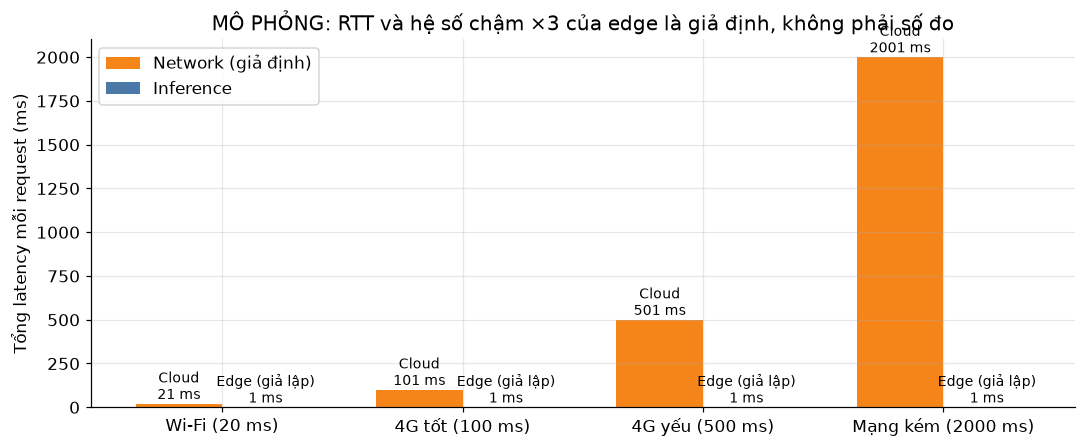

,scenario,rtt_ms,breakeven_slowdown_x
0,Wi-Fi (20 ms),20,100.2
1,4G tốt (100 ms),100,486.3
2,4G yếu (500 ms),500,2416.8
3,Mạng kém (2000 ms),2000,9656.2


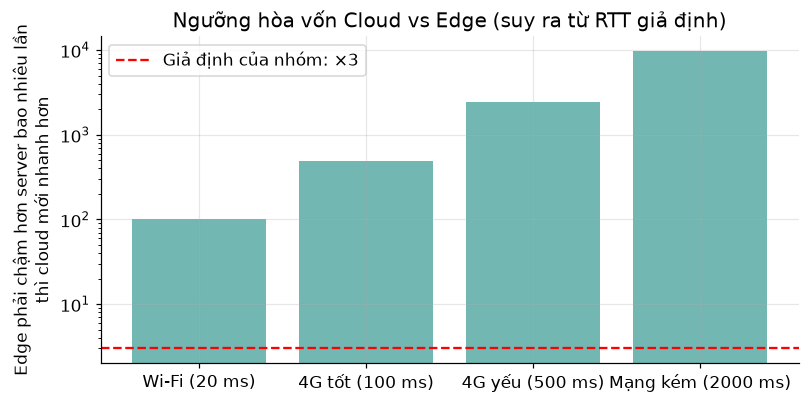

In [34]:
EDGE_SLOWDOWN = 3.0        # GIẢ ĐỊNH: thiết bị edge chậm hơn server 3 lần (KHÔNG đo trên thiết bị thật)
RTTS = {"Wi-Fi (20 ms)": 20, "4G tốt (100 ms)": 100, "4G yếu (500 ms)": 500, "Mạng kém (2000 ms)": 2000}
cloud_inf = RESULTS["fp32_bs1_p50"]                 # cùng baseline B1_BASE
int8_ms = RESULTS["int8_bs1_p50"]
edge_inf = int8_ms * EDGE_SLOWDOWN

rows = []
for sc, rtt in RTTS.items():
    rows.append({"scenario": sc, "where": "Cloud", "network_ms": rtt, "inference_ms": cloud_inf, "total_ms": rtt + cloud_inf})
    rows.append({"scenario": sc, "where": "Edge", "network_ms": 0, "inference_ms": edge_inf, "total_ms": edge_inf})
df_net = pd.DataFrame(rows); display(df_net.round(2)); df_net.to_csv("results/cloud_vs_edge_latency.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(RTTS)); w = 0.36
for off, where in [(-w / 2, "Cloud"), (w / 2, "Edge")]:
    d = df_net[df_net["where"] == where]
    lab = "Edge (giả lập)" if where == "Edge" else "Cloud"
    ax.bar(x + off, d["network_ms"], w, color="#F58518", label="Network (giả định)" if where == "Cloud" else None)
    ax.bar(x + off, d["inference_ms"], w, bottom=d["network_ms"], color="#4C78A8", label="Inference" if where == "Cloud" else None)
    for xi, tot in zip(x + off, d["total_ms"]):
        ax.text(xi, tot, f"{lab}\n{tot:.0f} ms", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(RTTS.keys()); ax.set_ylabel("Tổng latency mỗi request (ms)")
ax.set_title("MÔ PHỎNG: RTT và hệ số chậm ×3 của edge là giả định, không phải số đo"); ax.legend(loc="upper left")
savefig("fig11_cloud_vs_edge_latency")

# Ngưỡng hòa vốn: edge phải chậm hơn server bao nhiêu lần thì cloud mới nhanh hơn?
df_be = pd.DataFrame([{"scenario": sc, "rtt_ms": rtt, "breakeven_slowdown_x": (rtt + cloud_inf) / int8_ms}
                      for sc, rtt in RTTS.items()])
display(df_be.round(1)); df_be.to_csv("results/edge_breakeven.csv", index=False)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(df_be["scenario"], df_be["breakeven_slowdown_x"], color="#72B7B2")
ax.axhline(EDGE_SLOWDOWN, color="red", ls="--", label=f"Giả định của nhóm: ×{EDGE_SLOWDOWN:.0f}")
ax.set_yscale("log"); ax.set_ylabel("Edge phải chậm hơn server bao nhiêu lần\nthì cloud mới nhanh hơn")
ax.set_title("Ngưỡng hòa vốn Cloud vs Edge (suy ra từ RTT giả định)"); ax.legend()
savefig("fig11b_breakeven")

### 3.4 Chi phí cloud: nén model → ít máy hơn → bớt tiền
Ta ước tính **sơ bộ** số vCPU cần để phục vụ lưu lượng đỉnh, dựa trên **throughput vòng lặp kín đo được** (batch size 1, 1 luồng) của từng cấu hình.
> Luu y: Giá vCPU, QPS đỉnh và hệ số sử dụng là **giả định minh họa**. Phép tính giả định mở rộng tuyến tính theo số vCPU, không mô hình hóa hàng đợi, tính đồng thời, overhead của web server hay load balancer, nên đây không phải dự báo chi phí production. Số vCPU được báo cáo cả trước và sau khi làm tròn lên để tránh phóng đại mức tiết kiệm.

,config,qps_per_core_measured,vcpus_exact,vcpus_rounded_up,cost_month_usd_exact
0,PyTorch FP32,2733.35,36.59,37,1068.29
1,PyTorch INT8,4373.43,22.87,23,667.67
2,ONNX Runtime FP32,2723.30,36.72,37,1072.23


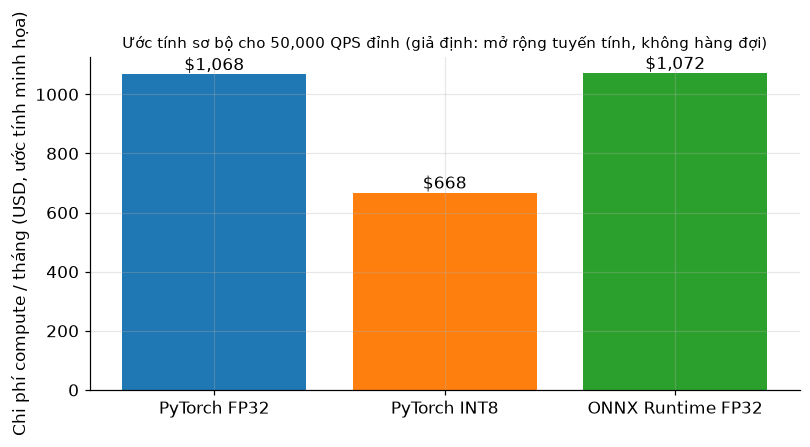

In [35]:
QPS_PEAK, UTIL, PRICE_VCPU_HOUR, HOURS_MONTH = 50_000, 0.5, 0.04, 730     # GIẢ ĐỊNH, thay bằng số của bạn

def closed_loop_qps(fn, seconds=2.0, warmup=50):
    for _ in range(warmup): fn()
    n, t0 = 0, time.perf_counter()
    while time.perf_counter() - t0 < seconds:
        fn(); n += 1
    return n / (time.perf_counter() - t0)

x1 = X_pool[:1]
cfgs = {"PyTorch FP32": lambda: run(base, x1), "PyTorch INT8": lambda: run(q_model, x1)}
if ONNX_OK:
    x1n = x1.numpy(); cfgs["ONNX Runtime FP32"] = lambda: sess_on.run(None, {"input": x1n})

rows = []
for name, fn in cfgs.items():
    qps = closed_loop_qps(fn)                       # throughput đo được, vòng lặp kín, 1 luồng
    cores_exact = QPS_PEAK / (qps * UTIL)
    rows.append({"config": name, "qps_per_core_measured": qps, "vcpus_exact": cores_exact,
                 "vcpus_rounded_up": math.ceil(cores_exact),
                 "cost_month_usd_exact": cores_exact * PRICE_VCPU_HOUR * HOURS_MONTH})
df_cost = pd.DataFrame(rows); display(df_cost.round(2)); df_cost.to_csv("results/cloud_cost_estimate.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(df_cost["config"], df_cost["cost_month_usd_exact"], color=plt.cm.tab10.colors[:len(df_cost)])
for i, v in enumerate(df_cost["cost_month_usd_exact"]): ax.text(i, v, f"${v:,.0f}", ha="center", va="bottom")
ax.set_ylabel("Chi phí compute / tháng (USD, ước tính minh họa)")
ax.set_title(f"Ước tính sơ bộ cho {QPS_PEAK:,} QPS đỉnh (giả định: mở rộng tuyến tính, không hàng đợi)", fontsize=10)
savefig("fig12_cloud_cost")

# Tổng hợp kết quả

In [36]:
print("Cấu hình máy:", SYSINFO, "\n")
rows = [
 ("Online vs Batch", "Throughput tăng khi batch lớn", f"{RESULTS['throughput_bs1']:.0f} → {RESULTS['throughput_best']:.0f} mẫu/s (x{RESULTS['throughput_best']/RESULTS['throughput_bs1']:.1f}, bs={RESULTS['best_batch_size']})"),
 ("Online vs Batch", "Throughput khi xử lý 4096 mẫu: batch so với online (đo thật vòng lặp 4096 request)", f"gấp {RESULTS['batch_total_speedup']:.1f}x (không phải latency mỗi request)"),
 ("Online vs Batch", "Lookup so với inference (bs=1)", f"{RESULTS['lookup_p50_ms']:.5f} ms so với {RESULTS['fp32_bs1_p50']:.3f} ms"),
]
c = df_comp.set_index("model")
q = c.loc["Quantized INT8"]; b0 = c.loc["Baseline FP32"]
rows += [("Compression", "INT8: size / latency bs1", f"{b0['state_dict_MB']/q['state_dict_MB']:.1f}x nhỏ hơn / {b0['latency_bs1_p50_ms']/q['latency_bs1_p50_ms']:.1f}x nhanh hơn, accuracy {b0['accuracy_%']:.2f}% → {q['accuracy_%']:.2f}%")]
kd25 = df_kd[(df_kd.label_fraction == 0.25) & (df_kd.method == "kd")].iloc[0]
rows.append(("Compression", "Student distilled so với student tự học (25% nhãn)",
             f"{n_params(base)/n_params(student_rep):.0f}x ít tham số hơn teacher; accuracy {kd25['acc_method_%']:.1f}% so với {kd25['acc_alone_%']:.1f}% "
             f"(hiệu số ghép cặp {kd25['paired_diff_mean']:+.2f} ± {kd25['paired_diff_se']:.2f})"))
if ONNX_OK:
    o = df_onnx.set_index("engine")
    rows.append(("Cloud/Edge", "ONNX RT (bật opt) so với PyTorch, bs=1", f"{o.loc['PyTorch','latency_bs1_p50_ms']/o.loc['ONNX RT (bật optimization)','latency_bs1_p50_ms']:.2f}x"))
rows.append(("Cloud/Edge", "Network RTT 100 ms so với inference", f"{100/RESULTS['fp32_bs1_p50']:.0f}x (network lớn hơn inference)"))
df_final = pd.DataFrame(rows, columns=["Phần", "Chỉ số", "Kết quả"])
display(df_final); df_final.to_csv("results/final_summary.csv", index=False)
print("\nFigures đã lưu:", sorted(os.listdir("figures")))
print("Bảng đã lưu  :", sorted(os.listdir("results")))

Cấu hình máy: Intel64 Family 6 Model 186 Stepping 2, GenuineIntel | 16 logical CPUs | Windows | Python 3.11.17 | torch 2.14.1+cpu | 1 thread | quant engine: onednn 



,Phần,Chỉ số,Kết quả
0,Online vs Batch,Throughput tăng khi batch lớn,"1305 → 13310 mẫu/s (x10.2, bs=4096)"
1,Online vs Batch,Throughput khi xử lý 4096 mẫu: batch so với on...,gấp 5.1x (không phải latency mỗi request)
2,Online vs Batch,Lookup so với inference (bs=1),0.00020 ms so với 0.766 ms
3,Compression,INT8: size / latency bs1,"4.0x nhỏ hơn / 3.7x nhanh hơn, accuracy 98.33%..."
4,Compression,Student distilled so với student tự học (25% n...,1255x ít tham số hơn teacher; accuracy 91.9% s...
5,Cloud/Edge,"ONNX RT (bật opt) so với PyTorch, bs=1",2.38x
6,Cloud/Edge,Network RTT 100 ms so với inference,131x (network lớn hơn inference)



Figures đã lưu: ['fig10_operator_fusion.png', 'fig11_cloud_vs_edge_latency.png', 'fig11b_breakeven.png', 'fig12_cloud_cost.png', 'fig1_online_latency_hist.png', 'fig2_batch_throughput_latency.png', 'fig3_precompute_vs_ondemand.png', 'fig4_hybrid_cache.png', 'fig5_pruning_sparsity_accuracy.png', 'fig6_lowrank.png', 'fig7_distillation.png', 'fig8_compression_summary.png', 'fig9_onnx_runtime.png']
Bảng đã lưu  : ['batch_vs_online.csv', 'cloud_cost_estimate.csv', 'cloud_vs_edge_latency.csv', 'compression_summary.csv', 'distillation.csv', 'edge_breakeven.csv', 'final_summary.csv', 'hybrid_cache.csv', 'lowrank.csv', 'onnx_runtime.csv', 'operator_fusion.csv', 'pruning.csv']
